# 4 · Project Template: Forecasting With Trees

<a href="https://colab.research.google.com/github/FH-Prevail/steyr_course/blob/main/notebooks/4_project_template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Advanced Data Analysis Techniques · Session 4: Forecasting With Tree-Based Models · Sina Mirshahi, FH OÖ Steyr*

Use this notebook if you choose **tree-based models** for your project. It follows the steps of the session, with every check you need for your report.

**Which module fits your question?** Choose Taha's (regression) when your main question is about relationships, effect sizes and their uncertainty. Choose Mehran's (clustering) when you look for groups of similar objects and have no target to predict. Choose this one when you want to forecast a number for future periods and can test the forecasts against later observations.

**How to use it**

1. Run it once **unchanged**: it works with the course data (`drinks_weekly.csv`) and shows what every step produces.
2. Then change the `# EDIT` lines to your own table, **one section at a time**, and run the notebook again from the top. Every check stops with a message that says what to fix.
3. Write your decisions in the cells marked **Your decision**. They become the backbone of your report.

**Your table** needs one row per series and regular period (one product per week, one warehouse per day, one region per month), a date column, a number to forecast, and inputs. With one single series, set `group = None`. The template forecasts the next period. A survey, an irregular list of shipments or a table without dates needs a different preparation and test: bring it to the consultation.

`# CHECK` lines give the result for the unchanged course data; with your data the numbers change. They can also differ a little from notebook 2: this template orders the inputs differently (a random forest then draws other inputs at its questions, even with the same seed) and sets forecasts below zero to zero.

| Section | Report criterion (weight) |
|---|---|
| 1 | Question and SCM relevance (15 %) |
| 2 and 3 | Data preparation and features (20 %) |
| 4 and 5 | Method and implementation (20 %) |
| 5 and 6 | Checks and experiments (25 %): your experiment on validation, the test once, the five checks |
| 7 and 8 | Interpretation and presentation (20 %) |

## 1 · Your question

> **Your decision (question):**
>
> - Which decision will use the forecast, and who makes it? *(course data: how many cases each product will sell next week, for the orders to the bottlers and the warehouse plan; stock and lead times then set the order itself)*
> - What exactly do you forecast, in which unit? *(cases per product per week)*
> - What is one row? *(one product in one week)*
> - When do you make the forecast, and how far ahead? *(Sunday evening, for the coming week)*
> - Why a tree-based model and not a regression or clustering? *(the effect of the weather and the promotions depends on the situation, and we want a forecast)*

## 2 · Load and check your table

**Edit** the file, its format, the names of the date, target and group columns, and how often a period comes (`frequency`). Missing targets must be resolved in the source data: never fill them from later periods, and remember that dropping a period changes what "the period before" means.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# EDIT: your file and its format
file = "https://raw.githubusercontent.com/FH-Prevail/steyr_course/main/data/drinks_weekly.csv"     # a link, or a path such as "data/my_table.csv" after you uploaded or mounted it
separator = ","                      # "," or ";"
decimal = "."                        # "." for 1.5, "," for 1,5
date_column = "week_start"           # the column with the date of the period
date_format = None                   # None for dates like 2025-01-31; "%d.%m.%Y" for 31.01.2025
target = "units"                     # the number you forecast
group = "product"                    # the series a row belongs to (product, store, route), or None for one series
frequency = "W-MON"                  # "W-MON" weekly on Mondays, "MS" monthly (first day), "D" daily

table = pd.read_csv(file, sep=separator, decimal=decimal)
needed = [date_column, target] + ([group] if group else [])
assert len(table), "The file has no rows."
assert len(set(needed)) == len(needed), "Date, target and group must be three different columns."
missing_columns = [c for c in needed if c not in table.columns]
assert not missing_columns, f"Not found: {missing_columns}. Check the names and the separator. The file has: {list(table.columns)}"
table[date_column] = pd.to_datetime(table[date_column], format=date_format, errors="coerce")
table[target] = pd.to_numeric(table[target], errors="coerce")
assert table[needed].notna().all().all(), "Some dates, targets or series labels are missing or unreadable: check date_format and decimal."
assert np.isfinite(table[target].to_numpy(dtype=float)).all(), "The target must hold finite numbers."
keys = ([group] if group else []) + [date_column]
assert not table.duplicated(keys).any(), "A period appears twice for a series: aggregate to one row per series and period first."
table = table.sort_values(keys).reset_index(drop=True)
for key, part in (table.groupby(group) if group else [("your series", table)]):
    expected = pd.date_range(part[date_column].min(), part[date_column].max(), freq=frequency)
    assert len(expected) == len(part) and (expected == pd.DatetimeIndex(part[date_column])).all(), \
        f"{key}: periods are missing or do not match frequency={frequency!r}. shift() counts rows, so every period must be there once."
file_columns = list(table.columns)                     # the columns of your file, before the template adds its own
print("rows and columns:", table.shape)
print("from", table[date_column].min().date(), "to", table[date_column].max().date(), "|", table[group].nunique() if group else 1, "series")
table.head()
# CHECK for the course data: (1672, 8), from 2022-01-03 to 2025-12-29, 8 series

rows and columns: (1672, 8)
from 2022-01-03 to 2025-12-29 | 8 series


,week_start,product,units,pallets,temp_forecast,temp_actual,discount_pct,holiday_days
0,2022-01-03,Apple spritzer,503,6.3,3.5,2.6,0,1
1,2022-01-10,Apple spritzer,563,7.0,0.2,0.1,0,0
2,2022-01-17,Apple spritzer,1000,12.5,1.4,2.1,20,0
3,2022-01-24,Apple spritzer,549,6.9,-2.8,-3.3,0,0
4,2022-01-31,Apple spritzer,993,12.4,5.6,4.4,20,0


## 3 · Inputs known at decision time

List your inputs in two groups. **Known inputs** are known for the period you forecast (a planned promotion, a holiday, a weather forecast). **History inputs** are built from the target itself, always from earlier periods only. Then fill in the table in **Your decision** for every column of your file, including the ones you leave out.

In [2]:
known_inputs = ["temp_forecast", "discount_pct", "holiday_days"]   # EDIT: known when you forecast (numbers or text)
not_known = ["pallets", "temp_actual"]     # EDIT: columns you must NOT use: unknown at decision time (say why in the report)
seasonal_lag = 52            # EDIT: about one year back: 52 (weekly, 364 days), 12 (monthly), 364 (daily)
lags = [1, seasonal_lag]     # EDIT: history inputs, in periods back; 1 = the period just before
window = 4                   # EDIT: the average of the last 4 periods
extra_categories = []        # EDIT: number columns that are really labels (a store number, a route code)

table = table[file_columns].copy()       # start from the columns of your file, so you can run this cell again after an edit
assert lags and all(type(k) is int and k > 0 for k in lags) and len(set(lags)) == len(lags), "lags: different whole numbers above 0."
assert type(window) is int and window > 0, "window: a whole number above 0."
absent = [c for c in known_inputs + not_known if c not in table.columns]
assert not absent, f"Not in your table: {absent}"
history = [f"lag_{k}" for k in lags] + [f"avg_last_{window}"]
clash = [c for c in history + ["season"] if c in table.columns]
assert not clash, f"Rename these columns of your file first, the template creates them: {clash}"
shortest = table.groupby(group).size().min() if group else len(table)
assert shortest > max(lags + [window]) + 10, "A series is too short for these lags: use shorter lags or a longer history."

past = table.groupby(group)[target] if group else table[target]
for k in lags:
    table[f"lag_{k}"] = past.shift(k)                       # k periods back, within each series
table[f"avg_last_{window}"] = (past.transform(lambda s: s.shift(1).rolling(window).mean()) if group
                               else table[target].shift(1).rolling(window).mean())


def season_of(dates):
    """The calendar input: the week of the year (weekly data), the month (monthly) or the weekday (daily)."""
    if frequency.startswith("W"):
        return dates.dt.isocalendar().week.astype(int)
    if frequency in ("MS", "ME", "M"):
        return dates.dt.month
    return dates.dt.dayofweek


table["season"] = season_of(table[date_column])
inputs = known_inputs + history + ["season"] + ([group] if group else [])
assert len(set(inputs)) == len(inputs), "An input appears twice."
assert not set(inputs) & set(not_known + [target, date_column]), "An input is the target, the date, or unknown at decision time."
model_table = table.dropna(subset=history).copy()
print(len(model_table), "rows with a complete history;", len(table) - len(model_table), "early rows only feed the history")
model_table[[date_column] + ([group] if group else []) + [target] + history].head()

1256 rows with a complete history; 416 early rows only feed the history


,week_start,product,units,lag_1,lag_52,avg_last_4
52,2023-01-02,Apple spritzer,505,505.0,503.0,725.25
53,2023-01-09,Apple spritzer,558,505.0,563.0,728.25
54,2023-01-16,Apple spritzer,540,558.0,1000.0,609.00
55,2023-01-23,Apple spritzer,523,540.0,549.0,527.00
56,2023-01-30,Apple spritzer,491,523.0,993.0,531.50


> **Your decision (inputs):** for every column, one line:
>
> | Column | Use it? | Known at decision time? | Why |
> |---|---|---|---|
> | *temp_forecast* | *yes* | *yes, the forecast on Sunday* | *drinks follow the weather* |
> | *pallets* | *no* | *no, only after the week* | *the target in another unit* |

## 4 · Three periods: learn, choose, test

The models learn from the first period, you **choose** on the validation period, and the test period is used **once**, at the end, after every choice is written down. Choose periods long enough to contain the situations that matter (for seasonal data, a whole year each).

**What the test means:** each test row is a separate forecast for the next period, made with the plans known then and the sales of the periods already finished (assumed final by then). Later test forecasts can therefore use earlier test sales. This does not test forecasting the whole test period at once.

In [3]:
validation_start = "2024-01-01"    # EDIT: the first date of the validation period (to choose)
test_start = "2025-01-01"          # EDIT: the first date of the test period (used once, at the end)
fill_missing = False               # EDIT: True fills missing number inputs with their median in the first period

dates = model_table[date_column]
is_fit = dates < validation_start
is_valid = (dates >= validation_start) & (dates < test_start)
is_test = dates >= test_start
is_train = ~is_test                                 # learn and validation together: what the final models learn from
for name, mask in [("learn", is_fit), ("validation", is_valid), ("test", is_test)]:
    assert mask.sum() >= 10, f"The {name} period has only {int(mask.sum())} rows: move validation_start and test_start."

text_inputs = [c for c in inputs if c == group or c in extra_categories or not pd.api.types.is_numeric_dtype(model_table[c])]
number_inputs = [c for c in inputs if c not in text_inputs]
gaps = model_table[inputs].isna().sum()
if gaps.any():
    assert fill_missing, f"Missing values in the inputs: {gaps[gaps > 0].to_dict()}. Fix them in the data, or set fill_missing = True."
    for c in gaps[gaps > 0].index:
        assert c in number_inputs, f"{c} is a text input: fill its missing values in the data."
        model_table[c] = model_table[c].fillna(model_table.loc[is_fit, c].median())    # learned from the first period only
categories = {c: sorted(model_table.loc[is_fit, c].astype(str).unique()) for c in text_inputs}   # learned from the first period


def check_inputs(rows):
    """Stop with a message if an input is missing, not a number, infinite, or a label the first period never had."""
    left = rows[inputs].isna().sum()
    assert not left.any(), f"Missing values left in the inputs: {left[left > 0].to_dict()}"
    assert all(pd.api.types.is_numeric_dtype(rows[c]) for c in number_inputs), "A measurement is not a number: check decimal."
    assert np.isfinite(rows[number_inputs].to_numpy(dtype=float)).all(), "A number input holds an infinite value."
    for c in text_inputs:
        unseen = sorted(set(rows[c].astype(str)) - set(categories[c]))
        assert not unseen, (f"{c}: labels absent from the first period, for example {unseen[:3]}. "
                            "Decide in the report how to handle new labels; do not just drop rows.")


def as_numbers(rows, columns=None):
    """The inputs as numbers: each text input becomes one 0/1 column per label of the first period."""
    columns = inputs if columns is None else columns
    X = rows[columns].copy()
    for c in columns:
        if c in text_inputs:
            X[c] = pd.Categorical(X[c].astype(str), categories=categories[c])
    X = pd.get_dummies(X, columns=[c for c in columns if c in text_inputs], dtype=int)
    X.columns = [re.sub(r"[^0-9A-Za-z_]", "_", str(c)) for c in X.columns]
    assert X.columns.is_unique, "Two inputs got the same name after cleaning: rename them in your file."
    return X


check_inputs(model_table)
if gaps.any():
    print("Filled with the median of the first period (say so in the report):", gaps[gaps > 0].to_dict())
X_all, y_all = as_numbers(model_table), model_table[target]
for name, mask in [("learn", is_fit), ("validation", is_valid), ("test", is_test)]:
    print(f"{name:11s}", int(mask.sum()), "rows,", dates[mask].min().date(), "to", dates[mask].max().date())
print("number inputs:", ", ".join(number_inputs), "| text inputs:", ", ".join(text_inputs) or "none")
# READ the line above: a measurement listed as a text input was misread (a decimal comma?): fix the format in section 2.
# CHECK for the course data: learn 416 rows from 2023-01-02; validation 424 rows from 2024-01-01; test 416 rows from 2025-01-06

learn       416 rows, 2023-01-02 to 2023-12-25
validation  424 rows, 2024-01-01 to 2024-12-30
test        416 rows, 2025-01-06 to 2025-12-29
number inputs: temp_forecast, discount_pct, holiday_days, lag_1, lag_52, avg_last_4, season | text inputs: product


## 5 · Choose on the validation period

Four methods: the **benchmark** repeats the value from `benchmark_lag` periods earlier; the **regression** of session 2; a **random forest** and **LightGBM**, with the knobs chosen in notebook 2 as starting values. Each learns from the first period and is scored on the validation period; the best one is your choice. Then your own **experiment**, also on the validation period. The test period stays closed until section 6.

In [4]:
import statsmodels.formula.api as smf
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor


def score(actual, forecast):
    """MAE: the average miss. WAPE: all misses as a percentage of the total. Bias: forecast minus actual."""
    if isinstance(actual, pd.Series) and isinstance(forecast, pd.Series):
        assert actual.index.equals(forecast.index), "Actuals and forecasts must belong to the same rows."
    a, f = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    assert a.ndim == 1 and a.size and a.shape == f.shape, "One forecast for every row, in one column."
    assert np.isfinite(a).all() and np.isfinite(f).all(), "Every actual value needs one finite forecast."
    miss, total = f - a, np.abs(a).sum()
    return pd.Series({"MAE": np.abs(miss).mean(), "WAPE, %": np.abs(miss).sum() / total * 100 if total else np.nan, "Bias": miss.mean()})


benchmark_lag = seasonal_lag   # EDIT: the period the benchmark repeats (one of the lags)
assert benchmark_lag in lags, "benchmark_lag must be one of the lags of section 3."
clip_at_zero = True            # EDIT: sales cannot be negative; False if your target can be
models = {"Random forest": RandomForestRegressor(n_estimators=300, max_features=0.33, random_state=42, n_jobs=-1),
          "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=7, min_child_samples=10,
                                    random_state=42, verbose=-1)}
q = lambda c: f"Q({c!r})"                                     # quotes any column name for the formula
formula = q(target) + " ~ " + " + ".join(f"C({q(c)})" if c in text_inputs else q(c) for c in inputs)


def policy(prediction):
    """The same rule for every forecast: below zero becomes zero when clip_at_zero is True."""
    prediction = np.asarray(prediction, dtype=float)
    return np.clip(prediction, 0, None) if clip_at_zero else prediction


def forecast_with(method, learn_mask, rows):
    """Learn `method` from the rows of learn_mask and forecast `rows`."""
    if method == "Benchmark":
        f = rows[f"lag_{benchmark_lag}"].to_numpy(float)
    elif method == "Linear regression":
        as_text = {c: object for c in text_inputs}
        f = smf.ols(formula, data=model_table[learn_mask].astype(as_text)).fit().predict(rows.astype(as_text)).to_numpy(float)
    else:
        f = clone(models[method]).fit(X_all[learn_mask], y_all[learn_mask]).predict(as_numbers(rows))
    return policy(f)


METHODS = ["Benchmark", "Linear regression", "Random forest", "LightGBM"]
validation = pd.DataFrame({m: score(y_all[is_valid], forecast_with(m, is_fit, model_table[is_valid])) for m in METHODS}).T
assert validation["WAPE, %"].notna().all(), "WAPE is undefined (the actual values add up to zero): choose by MAE instead."
chosen_method = validation["WAPE, %"].idxmin()
print("Chosen on the validation period:", chosen_method)
validation.round(1)
# CHECK for the course data: chosen Random forest; validation WAPE 16.4 %

Chosen on the validation period: Random forest


,MAE,"WAPE, %",Bias
Benchmark,242.3,27.7,-37.0
Linear regression,184.5,21.1,-20.3
Random forest,143.1,16.4,-29.6
LightGBM,147.1,16.8,-27.9


In [5]:
# EDIT: your what-if experiment, judged on the validation period. Example: LightGBM without the temperature forecast.
experiment_inputs = [c for c in inputs if c != "temp_forecast"]
X_exp = as_numbers(model_table, experiment_inputs)
exp = clone(models["LightGBM"]).fit(X_exp[is_fit], y_all[is_fit])
print("LightGBM on the validation period, all inputs:     ", round(validation.loc["LightGBM", "WAPE, %"], 1), "%")
print("LightGBM on the validation period, the experiment: ", round(score(y_all[is_valid], policy(exp.predict(X_exp[is_valid])))["WAPE, %"], 1), "%")
# CHECK for the course data: 16.8 % with all inputs, 20.0 % without the temperature forecast

LightGBM on the validation period, all inputs:      16.8 %
LightGBM on the validation period, the experiment:  20.0 %


> **Your decision (method), written down before you open the test:** Which methods did you compare, with which settings? Which one did the validation period choose? What did your experiment change on the validation period? If you adopt a change (an input, a knob), make it in section 3 or 5 and run again from there, so `chosen_method` and the models use it. Changes made after seeing the test results would need another untouched period to be tested fairly.

## 6 · The test, once, and the checks

All four methods learn again from both periods and forecast the test period. Then the five checks from the session.

In [6]:
forecasts = pd.DataFrame({m: forecast_with(m, is_train, model_table[is_test]) for m in METHODS}, index=model_table.index[is_test])
results = pd.DataFrame({m: score(y_all[is_test], forecasts[m]) for m in METHODS}).T
print("The test period, used once. Your choice:", chosen_method)
results.round(1)
# CHECK for the course data: test WAPE: benchmark 29.1 %, regression 20.8 %, forest 15.8 %, LightGBM 14.8 %

The test period, used once. Your choice: Random forest


,MAE,"WAPE, %",Bias
Benchmark,266.2,29.1,-34.7
Linear regression,190.3,20.8,-7.2
Random forest,144.4,15.8,-31.0
LightGBM,135.3,14.8,-8.7


On the course data the validation period chooses the **Random forest**. Compare its test result with the others: when methods are close on the validation period, their order can change on the test period. Report what you chose on the validation period and why, not the method with the best test number.

In [7]:
seen = score(y_all[is_train], forecast_with(chosen_method, is_train, model_table[is_train]))["WAPE, %"]
print("1. Split by time:          learn to", dates[is_fit].max().date(), "| validation to", dates[is_valid].max().date(),
      "| test from", dates[is_test].min().date())
print("2. Inputs known in time:   ", ", ".join(inputs), "| left out:", ", ".join(not_known) or "none")
print("3. Against the benchmark:  ", chosen_method, round(results.loc[chosen_method, "WAPE, %"], 1), "% against",
      round(results.loc["Benchmark", "WAPE, %"], 1), "% on the test period")
print("4. Seen against new data:  ", chosen_method, round(seen, 1), "% on the rows it learned from,",
      round(results.loc[chosen_method, "WAPE, %"], 1), "% on the test period")
print("5. Look at the chart below: below zero, ceilings, copies of the last period, periods unlike the past")
if group:                    # the WAPE of the chosen method for every series (undefined where the series sold nothing)
    tested = model_table[is_test]
    per_series = {key: score(part[target], forecasts.loc[part.index, chosen_method])["WAPE, %"] for key, part in tested.groupby(group)}
    print(pd.Series(per_series).sort_values().round(1).to_string())

1. Split by time:          learn to 2023-12-25 | validation to 2024-12-30 | test from 2025-01-06
2. Inputs known in time:    temp_forecast, discount_pct, holiday_days, lag_1, lag_52, avg_last_4, season, product | left out: pallets, temp_actual
3. Against the benchmark:   Random forest 15.8 % against 29.1 % on the test period
4. Seen against new data:   Random forest 5.2 % on the rows it learned from, 15.8 % on the test period
5. Look at the chart below: below zero, ceilings, copies of the last period, periods unlike the past
Orange juice       8.7
Lager beer        13.7
Apple spritzer    14.0
Energy drink      15.6
Mineral water     15.8
Mulled wine       20.8
Radler            23.0
Ice tea           23.0


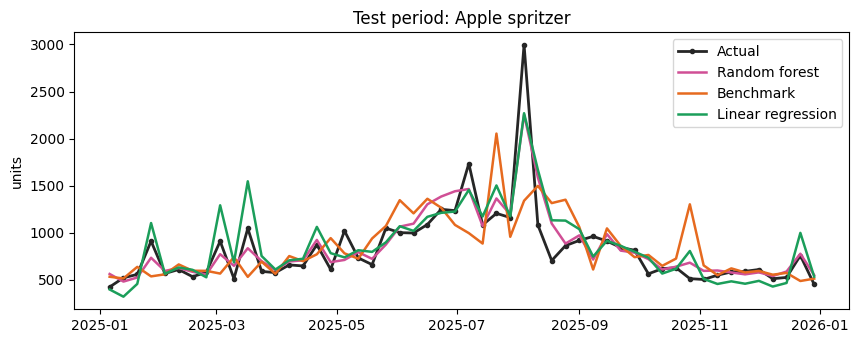

In [8]:
show_group = model_table.loc[is_test, group].iloc[0] if group else None    # EDIT: one series to look at
part = model_table[is_test] if not group else model_table[is_test & (model_table[group] == show_group)]
assert len(part), f"No test rows for {show_group!r}."
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(part[date_column], part[target], color="#262626", lw=2, marker="o", ms=3, label="Actual")
colours = {"Benchmark": "#E66A1F", "Linear regression": "#1B9E5A", "Random forest": "#D04F95", "LightGBM": "#0B5CAD"}
for m in dict.fromkeys([chosen_method, "Benchmark", "Linear regression"]):
    ax.plot(part[date_column], forecasts.loc[part.index, m], color=colours[m], lw=1.8, label=m)
ax.set(title=f"Test period: {show_group if group else target}", ylabel=target)
ax.legend()
plt.show()

> **Your decision (checks):** What did each of the five checks show? What does your experiment of section 5 tell you about your data?

## 7 · OPTIONAL: explain the LightGBM model

What LightGBM relies on (permutation importance on the test period: other inputs shuffled within each series, the series label swapped between rows; shuffling can create unusual combinations, and related inputs can share information), and one forecast split into a reference plus one share per input (SHAP values: they describe the raw model forecast, not the effect of changing an input). If you chose another method, explain that one in your report instead.

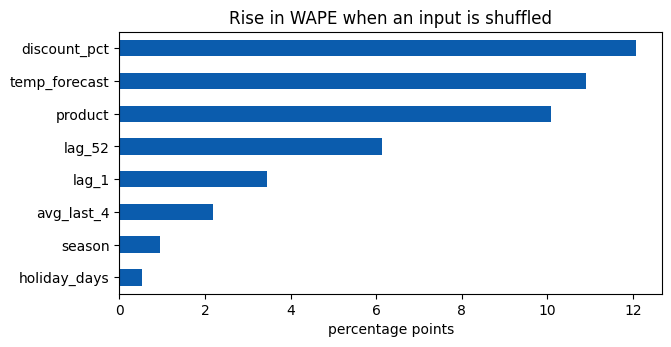

Raw forecast: 470.8 | after the zero rule: 470.8 | reference (average forecast): 859.0 | actual: 422


avg_last_4      -111.9
temp_forecast    -94.7
lag_52           -84.3
discount_pct     -55.7
season            30.6
product          -30.4
holiday_days     -30.0
lag_1            -11.9
dtype: float64

In [9]:
final_lgbm = clone(models["LightGBM"]).fit(X_all[is_train], y_all[is_train])
X_test = X_all[is_test]
feature_columns = {c: as_numbers(model_table.iloc[:5], [c]).columns.tolist() for c in inputs}   # the 0/1 columns of each input
rng = np.random.default_rng(0)
base = score(y_all[is_test], policy(final_lgbm.predict(X_test)))["WAPE, %"]
series_of = model_table.loc[is_test, group].astype(str).to_numpy() if group else np.zeros(int(is_test.sum()))
rise = {}
for c in inputs:
    rises = []
    for _ in range(3):
        order = np.arange(len(X_test))
        if c == group:                                   # swap the series between rows
            order = rng.permutation(len(X_test))
        else:                                            # shuffle within each series
            for g in np.unique(series_of):
                where = np.flatnonzero(series_of == g)
                order[where] = rng.permutation(where)
        shuffled = X_test.copy()
        shuffled[feature_columns[c]] = X_test[feature_columns[c]].to_numpy()[order]
        rises.append(score(y_all[is_test], policy(final_lgbm.predict(shuffled)))["WAPE, %"] - base)
    rise[c] = np.mean(rises)
pd.Series(rise).sort_values().plot.barh(color="#0B5CAD", figsize=(7, 3.4), title="Rise in WAPE when an input is shuffled")
plt.xlabel("percentage points")
plt.show()

i = 0                        # EDIT: which test row to explain (0 = the first)
contrib = pd.Series(final_lgbm.predict(X_test.iloc[[i]], pred_contrib=True)[0], index=list(X_test.columns) + ["reference"])
shares = pd.Series({c: contrib[feature_columns[c]].sum() for c in inputs})
raw = final_lgbm.predict(X_test.iloc[[i]])[0]
assert np.isclose(contrib["reference"] + shares.sum(), raw)      # reference plus shares = the raw forecast
print("Raw forecast:", round(raw, 1), "| after the zero rule:", round(policy([raw])[0], 1),
      "| reference (average forecast):", round(contrib["reference"], 1), "| actual:", y_all[is_test].iloc[i])
shares.sort_values(key=abs, ascending=False).round(1)

> **Your decision (interpretation):** Which inputs does the model rely on, and does that make business sense? Explain one forecast in one sentence a manager understands. Where should nobody trust the model (periods unlike the past, new series, small series)?

## 8 · Your forecast and the decision

The chosen method learns from **all** your data and forecasts the **next period**. The history inputs of the next period come from your data; the known inputs (your plan, your weather forecast) you fill in yourself. The plan below gives every series the same values; if plans differ by series, join a plan table by series and date with `validate="one_to_one"` and check it is complete before the forecast.

In [10]:
step = pd.tseries.frequencies.to_offset(frequency)
rows = []
for key, part in (table.groupby(group) if group else [(None, table)]):
    values = part[target].to_numpy()                       # the series up to the last known period
    new = {date_column: part[date_column].max() + step}
    if group:
        new[group] = key
    for k in lags:
        new[f"lag_{k}"] = values[-k]                       # k periods before the next one
    new[f"avg_last_{window}"] = values[-window:].mean()
    rows.append(new)
next_period = pd.DataFrame(rows)
next_period["season"] = season_of(next_period[date_column])
assert next_period[date_column].nunique() == 1, "The series end on different dates: choose one common forecast date."

plan = {"temp_forecast": 2.0, "discount_pct": 0, "holiday_days": 1}    # EDIT: one value for each known input
assert set(plan) == set(known_inputs), f"Give exactly one value for each known input: {known_inputs}"
for c, value in plan.items():
    next_period[c] = value
check_inputs(next_period)
next_period["forecast"] = forecast_with(chosen_method, np.ones(len(model_table), dtype=bool), next_period)
assert np.isfinite(next_period["forecast"]).all(), "Every series needs one finite forecast."
print("Forecast with", chosen_method, "for the period starting", next_period[date_column].iloc[0].date())
next_period[([group] if group else []) + [date_column, "forecast"]].round({"forecast": 1})
# CHECK for the course data: Random forest, the week of 2026-01-05; Mineral water 1,578.0 cases

Forecast with Random forest for the period starting 2026-01-05


,product,week_start,forecast
0,Apple spritzer,2026-01-05,474.1
1,Energy drink,2026-01-05,389.6
2,Ice tea,2026-01-05,197.4
3,Lager beer,2026-01-05,1155.1
4,Mineral water,2026-01-05,1578.0
5,Mulled wine,2026-01-05,27.4
6,Orange juice,2026-01-05,561.3
7,Radler,2026-01-05,60.3


> **Your decision (the answer to your question):** What do you recommend, based on the forecast? How large were the errors on the test period (MAE, WAPE), and were the forecasts more often too high or too low? What does that mean for the decision? (Neither number sets a safety stock by itself.) What would you do next with more time or data?

**Document your use of AI** in the report: where you used it (for example "to adapt section 2 to my file") and how you checked the result. Code that runs is not code that is right.